# Research Paper Classification Using Machine Learning

## Project Overview
This project aims to classify research papers into Science, Business, and Social Science categories using machine learning and NLP techniques. The workflow includes data preprocessing, feature extraction using TF-IDF, model training, evaluation, and hyperparameter tuning to identify the best-performing classifier. The best-performing model was then used to predict the category of my own research paper based on it's abstract.

## 1. Collect labelled dataset
The three datasets taken from Scopus are loaded separately, and a category label is assigned to each research paper. All the datasets were then combined into one DataFrame to prepare the data for classification.

In [3]:
import pandas as pd

science = pd.read_csv("data/science_abstract_dataset.csv")
business = pd.read_csv("data/business_abstract_dataset.csv")
social_science = pd.read_csv("data/social_science_abstract_dataset.csv")

science["Label"] = "Science"
business["Label"] = "Business"
social_science["Label"] = "Social Science"

df = pd.concat(
    [science, business, social_science],
    ignore_index=True
)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Label"].value_counts())

Dataset shape: (1200, 3)

Class distribution:
Label
Science           400
Business          400
Social Science    400
Name: count, dtype: int64


## 2. Handling redundancy in dataset collected through Scopus
This step identifies missing values, duplicate records, and repeated titles to improve dataset quality. Duplicate and unclear records are then removed to make the dataset more reliable for classification.

In [4]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

# Check duplicate titles
print("Duplicate titles:", df["Title"].duplicated().sum())

# Check empty abstracts
print(
    "Empty abstracts:",
    df["Abstract"].fillna("").str.strip().eq("").sum()
)

Missing values:
Title       0
Abstract    0
Label       0
dtype: int64

Exact duplicate rows: 0
Duplicate titles: 8
Empty abstracts: 0


In [5]:
# Display all rows with duplicate titles
duplicate_titles = df[
    df["Title"].duplicated(keep=False)
].sort_values("Title")

duplicate_titles[["Title", "Label"]]

,Title,Label
77,"15th Computer Science Online Conference, CSOC ...",Science
138,"15th Computer Science Online Conference, CSOC ...",Science
145,"15th Computer Science Online Conference, CSOC ...",Science
201,"15th Computer Science Online Conference, CSOC ...",Science
461,BIBLIOMETRIC ANALYSIS OF PUBLICATIONS ON RECOM...,Business
849,BIBLIOMETRIC ANALYSIS OF PUBLICATIONS ON RECOM...,Social Science
426,Bridging prediction with planning: Integrating...,Business
821,Bridging prediction with planning: Integrating...,Social Science
451,Cyberbullying Detection in Schools Using Machi...,Business
842,Cyberbullying Detection in Schools Using Machi...,Social Science


In [6]:
# Keep a copy of the original combined dataset
df_original = df.copy()

# Remove titles assigned to more than one category
cross_category_titles = (
    df.groupby("Title")["Label"]
    .nunique()
)

conflicting_titles = cross_category_titles[
    cross_category_titles > 1
].index

df_clean = df[
    ~df["Title"].isin(conflicting_titles)
].copy()

print("Original rows:", len(df_original))
print("Rows removed:", len(df_original) - len(df_clean))
print("Rows remaining:", len(df_clean))

print("\nClass distribution after removal:")
print(df_clean["Label"].value_counts())

Original rows: 1200
Rows removed: 10
Rows remaining: 1190

Class distribution after removal:
Label
Science           400
Business          395
Social Science    395
Name: count, dtype: int64


Duplicate and ambiguous records are removed to reduce redundancy and improve the reliability of classification.

In [7]:
science_duplicates = df_clean[
    (df_clean["Label"] == "Science")
    & (df_clean["Title"].duplicated(keep=False))
].sort_values("Title")

for _, row in science_duplicates.iterrows():
    print("=" * 80)
    print("Title:", row["Title"])
    print("Abstract:", row["Abstract"])
    print()

Title: 15th Computer Science Online Conference, CSOC 2026
Abstract: The proceedings contain 207 papers. The special focus in this conference is on  Computer Science. The topics include: Risk, Ownership, and Value Creation: How ERM and Managerial Stakes Shape Technology Firms in Emerging Markets; deep Learning-Based Microscopic Analysis of Medical Plant Images; How AI Is Transforming Banking: Enhancing Risk Management, Efficiency and Customer Trust; creative Technologies and Media Design in the Context of Artificial Intelligence: Trends and Challenges; microeconomic Determinants of Financial Inclusion in Peru During 2024; emergency Medical Services Evolution and Resilience Across Prehospital Care Models and Digital Innovation; a Model of Automatic Redistribution of Pursuers Among Targets in a Group Pursuit Problem; A Model for Operational Evaluation of Grain Crop Yields Based on the Vegetation Index NDVI; architecture-Oriented Design and Analysis of Integrated User Interfaces in Cross-P

In [8]:
# Remove conference-level records that aren't individual paper abstracts
conference_title = "15th Computer Science Online Conference, CSOC 2026"

conference_mask = df_clean["Title"].str.strip().eq(conference_title)

print("Conference-level records found:", conference_mask.sum())

df_clean = df_clean[~conference_mask].copy()

print("Rows remaining:", len(df_clean))
print("\nClass distribution:")
print(df_clean["Label"].value_counts())

Conference-level records found: 4
Rows remaining: 1186

Class distribution:
Label
Science           396
Business          395
Social Science    395
Name: count, dtype: int64


In [9]:
print("Duplicate titles remaining:", df_clean["Title"].duplicated().sum())
print("Duplicate abstracts remaining:", df_clean["Abstract"].duplicated().sum())

Duplicate titles remaining: 0
Duplicate abstracts remaining: 3


In [10]:
# Find all rows whose abstracts are duplicated
duplicate_abstracts = df_clean[
    df_clean["Abstract"].duplicated(keep=False)
].sort_values("Abstract")

for _, row in duplicate_abstracts.iterrows():
    print("=" * 80)
    print("Title:", row["Title"])
    print("Label:", row["Label"])
    print("Abstract:", row["Abstract"][:500])
    print()

Title: AI Applications - Transformers, Speech and Language Technologies
Label: Business
Abstract: The 2nd edition of the Bordeaux Summer School–Energy-Efficient Embedded Artificial Intelligence (E3AI) builds on the foundations and success of the 2023 inaugural program. While the first edition offered essential training in energy-efficient machine learning, edge computing, and emerging nanoscale technologies, the 2025 edition expands significantly in both scope and technical depth. Unlike the first edition, which centered primarily on the hardware–software interface for embedded AI, the 2025 

Title: Past, Present and Future Fascinating Electronics
Label: Business
Abstract: The 2nd edition of the Bordeaux Summer School–Energy-Efficient Embedded Artificial Intelligence (E3AI) builds on the foundations and success of the 2023 inaugural program. While the first edition offered essential training in energy-efficient machine learning, edge computing, and emerging nanoscale technologies, the 

In [11]:
# Keep the first occurrence of each abstract
before = len(df_clean)

df_clean = df_clean.drop_duplicates(
    subset=["Abstract"],
    keep="first"
).copy()

print("Rows removed:", before - len(df_clean))
print("Rows remaining:", len(df_clean))

print("\nClass distribution:")
print(df_clean["Label"].value_counts())

print("\nDuplicate titles:", df_clean["Title"].duplicated().sum())
print("Duplicate abstracts:", df_clean["Abstract"].duplicated().sum())

Rows removed: 3
Rows remaining: 1183

Class distribution:
Label
Science           396
Social Science    395
Business          392
Name: count, dtype: int64

Duplicate titles: 0
Duplicate abstracts: 0


In [12]:
# Save the cleaned dataset
df_clean.to_csv(
    "data/cleaned_research_abstracts.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Total records:", len(df_clean))
print("\nClass distribution:")
print(df_clean["Label"].value_counts())

Cleaned dataset saved successfully!
Total records: 1183

Class distribution:
Label
Science           396
Social Science    395
Business          392
Name: count, dtype: int64


The cleaned dataset is now saved as a CSV file for further preprocessing.

## 3. Text Preprocessing
The research paper abstracts are preprocessed to make the text suitable for machine learning. This included text cleaning, stop-word removal, and lemmatization.

### 3.1 Text cleaning
The abstracts are converted to lowercase and unnecessary punctuation and special characters are removed.

In [13]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[-–—]", " ", text)
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [14]:
# testing the clean_text function on a sample abstract
sample = df_clean["Abstract"].iloc[0]

print("Original Abstract:\n", sample)
print("\nCleaned Abstract:\n", clean_text(sample))

Original Abstract:
 Predicting the stress–strain behaviors of additively manufactured materials is crucial for part qualification in additive manufacturing (AM). Conventional physics-based constitutive models of materials have limitations, such as oversimplification of material properties and narrow applicability to limited strain rates, while purely data-driven machine learning (ML) models often lack physical consistency and interpretability. To address these issues, we introduce a physics-informed machine learning (PIML) framework that leverages physical laws in elastic and plastic regions to improve the predictive performance and physical consistency when predicting the stress–strain curves of additively manufactured polymers and metals. A polynomial regression model is first used to predict the yield point based on AM process parameters, and then the stress–strain curves are segmented into elastic and plastic regions using the predicted yield point. Two long short-term memory (LSTM

In [15]:
df_clean["Cleaned_Abstract"] = df_clean["Abstract"].apply(clean_text)

df_clean[["Abstract", "Cleaned_Abstract"]].head()

,Abstract,Cleaned_Abstract
0,Predicting the stress–strain behaviors of addi...,predicting the stress strain behaviors of addi...
1,This paper systematically explores and evaluat...,this paper systematically explores and evaluat...
2,Inverter-dominated transmission grids challeng...,inverter dominated transmission grids challeng...
3,Hybrid simulation integrating traditional nume...,hybrid simulation integrating traditional nume...
4,Thermo-oxidative (TO) preaging significantly i...,thermo oxidative to preaging significantly inf...


### 3.2 Stop-word removal
Common words that do not contribute much to classification are removed from the abstracts. Words such as “not” “no” & “nor” are preserved to avoid losing important meaning.

In [16]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

# Preserve important negation words
stop_words.discard("not")
stop_words.discard("no")
stop_words.discard("nor")

def remove_stopwords(text):
    words = text.split()
    filtered_words = [word for word in words if word not in stop_words]
    return " ".join(filtered_words)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\prana\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [17]:
df_clean["Stopword_Removed_Abstract"] = (
    df_clean["Cleaned_Abstract"].apply(remove_stopwords)
)

df_clean[["Cleaned_Abstract", "Stopword_Removed_Abstract"]].head()

,Cleaned_Abstract,Stopword_Removed_Abstract
0,predicting the stress strain behaviors of addi...,predicting stress strain behaviors additively ...
1,this paper systematically explores and evaluat...,paper systematically explores evaluates ai dri...
2,inverter dominated transmission grids challeng...,inverter dominated transmission grids challeng...
3,hybrid simulation integrating traditional nume...,hybrid simulation integrating traditional nume...
4,thermo oxidative to preaging significantly inf...,thermo oxidative preaging significantly influe...


### 3.3 Lemmatization
Words are now converted to their base forms using POS-aware lemmatization. This helps group different forms of the same word while preserving their meaning.

In [18]:
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer

# Check whether WordNet is available
lemmatizer = WordNetLemmatizer()

try:
    wordnet.synsets("dog")
    WORDNET_AVAILABLE = True
except LookupError:
    WORDNET_AVAILABLE = False

print("WordNet corpus available:", WORDNET_AVAILABLE)

if not WORDNET_AVAILABLE:
    print(
        "To enable WordNet lemmatization, run "
        "nltk.download('wordnet') once with internet access."
    )

WordNet corpus available: True


In [19]:
try:
    nltk.pos_tag(["running"])
    POS_TAGGER_AVAILABLE = True
except LookupError:
    POS_TAGGER_AVAILABLE = False

print("POS tagger available:", POS_TAGGER_AVAILABLE)

POS tagger available: True


In [20]:
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"  # Adjective
    elif tag.startswith("V"):
        return "v"  # Verb
    elif tag.startswith("N"):
        return "n"  # Noun
    elif tag.startswith("R"):
        return "r"  # Adverb
    else:
        return "n"


def lemmatize_text(text):
    words = text.split()
    tagged_words = nltk.pos_tag(words)

    lemmatized_words = [
        lemmatizer.lemmatize(word, get_wordnet_pos(tag))
        for word, tag in tagged_words
    ]

    return " ".join(lemmatized_words)

In [21]:
if WORDNET_AVAILABLE and POS_TAGGER_AVAILABLE:
    df_clean["Lemmatized_Abstract"] = (
        df_clean["Stopword_Removed_Abstract"].apply(lemmatize_text)
    )
    print("POS-aware lemmatization completed successfully.")
else:
    df_clean["Lemmatized_Abstract"] = (
        df_clean["Stopword_Removed_Abstract"]
    )
    print("Lemmatization skipped. Using stop-word-removed text.")

POS-aware lemmatization completed successfully.


In [22]:
df_clean[
    ["Stopword_Removed_Abstract", "Lemmatized_Abstract"]
].head()

,Stopword_Removed_Abstract,Lemmatized_Abstract
0,predicting stress strain behaviors additively ...,predict stress strain behavior additively manu...
1,paper systematically explores evaluates ai dri...,paper systematically explore evaluate ai drive...
2,inverter dominated transmission grids challeng...,inverter dominate transmission grid challenge ...
3,hybrid simulation integrating traditional nume...,hybrid simulation integrate traditional numeri...
4,thermo oxidative preaging significantly influe...,thermo oxidative preaging significantly influe...


### Why I didn't performed Tokenization separately:

A separate tokenization step is not required because the TF-IDF vectorizer automatically tokenizes the preprocessed text into words while converting it into numerical features. So I ommitted this redundant step.

## 4. Feature extraction
First the dataset is split into trainig and testing data in 80:20 ratio, then the preprocessed abstracts are converted into numerical features using TF-IDF which assigns weights to words based on their importance in a document relative to the entire dataset. These numerical representations will further be used as input for the 6 classifiers.

In [23]:
from sklearn.model_selection import train_test_split

X = df_clean["Lemmatized_Abstract"]
y = df_clean["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 946
Testing samples: 237

Training class distribution:
Label
Science           317
Social Science    316
Business          313
Name: count, dtype: int64

Testing class distribution:
Label
Business          79
Social Science    79
Science           79
Name: count, dtype: int64


In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)
print("Number of features:", len(vectorizer.get_feature_names_out()))

Training matrix shape: (946, 13499)
Testing matrix shape: (237, 13499)
Number of features: 13499


## 5. Training and evaluation of classifiers
The TF-IDF features are used to train 6 different machine learning classifiers for research paper classification. The models are evaluated using performance metrics such as accuracy, precision, recall, and F1-score to compare their classification performance.

### 5.1 Logistic Regression
Logistic Regression is trained on the TF-IDF features to classify research papers into Science, Business, and Social Science. It achieves an accuracy of **79.75%** on the test set.

In [25]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [26]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", round(accuracy_lr, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.7975

Classification Report:
                precision    recall  f1-score   support

      Business       0.82      0.80      0.81        79
       Science       0.76      0.80      0.78        79
Social Science       0.82      0.80      0.81        79

      accuracy                           0.80       237
     macro avg       0.80      0.80      0.80       237
  weighted avg       0.80      0.80      0.80       237



### 5.2 Decision Tree

A Decision Tree classifier is trained using the TF-IDF features to classify research papers into the three categories. It achieves an accuracy of **75.95%** on the test set.

In [27]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_tfidf, y_train)

y_pred_dt = dt_model.predict(X_test_tfidf)

print("Decision Tree training completed.")

Decision Tree training completed.


In [28]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", round(accuracy_dt, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.7595

Classification Report:
                precision    recall  f1-score   support

      Business       0.78      0.76      0.77        79
       Science       0.76      0.81      0.79        79
Social Science       0.74      0.71      0.72        79

      accuracy                           0.76       237
     macro avg       0.76      0.76      0.76       237
  weighted avg       0.76      0.76      0.76       237



### 5.3 Naive Bayes

The Multinomial Naive Bayes classifier is trained on the TF-IDF features to categorize research paper abstracts. It achieves an accuracy of **78.06%** on the test set.

In [29]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)

print("Naive Bayes training completed.")

Naive Bayes training completed.


In [30]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", round(accuracy_nb, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.7806

Classification Report:
                precision    recall  f1-score   support

      Business       0.77      0.81      0.79        79
       Science       0.76      0.82      0.79        79
Social Science       0.82      0.71      0.76        79

      accuracy                           0.78       237
     macro avg       0.78      0.78      0.78       237
  weighted avg       0.78      0.78      0.78       237



### 5.4 k-Nearest Neighbors (kNN)

The kNN classifier, with 5 neighbors, is trained using the TF-IDF features to classify research paper abstracts. It achieves an accuracy of **71.31%** on the test set.

In [31]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_tfidf, y_train)

y_pred_knn = knn_model.predict(X_test_tfidf)

print("kNN training completed.")

kNN training completed.


In [32]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("kNN Accuracy:", round(accuracy_knn, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

kNN Accuracy: 0.7131

Classification Report:
                precision    recall  f1-score   support

      Business       0.62      0.86      0.72        79
       Science       0.75      0.62      0.68        79
Social Science       0.83      0.66      0.73        79

      accuracy                           0.71       237
     macro avg       0.73      0.71      0.71       237
  weighted avg       0.73      0.71      0.71       237



### 5.5 Support Vector Machine (SVM)

A Linear Support Vector Machine is trained on the TF-IDF features to classify research papers into the three categories. It achieves an accuracy of **82.28%** on the test set.

In [33]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

print("SVM training completed.")

SVM training completed.


In [34]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", round(accuracy_svm, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.8228

Classification Report:
                precision    recall  f1-score   support

      Business       0.87      0.85      0.86        79
       Science       0.78      0.82      0.80        79
Social Science       0.82      0.80      0.81        79

      accuracy                           0.82       237
     macro avg       0.82      0.82      0.82       237
  weighted avg       0.82      0.82      0.82       237



### 5.6 Random Forest

A Random Forest classifier with 100 estimators is trained using the TF-IDF features to classify research paper abstracts. It achieves an accuracy of **80.59%** on the test set.

In [35]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_tfidf, y_train)

y_pred_rf = rf_model.predict(X_test_tfidf)

print("Random Forest training completed.")

Random Forest training completed.


In [36]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(accuracy_rf, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.8059

Classification Report:
                precision    recall  f1-score   support

      Business       0.81      0.84      0.82        79
       Science       0.78      0.84      0.80        79
Social Science       0.83      0.75      0.79        79

      accuracy                           0.81       237
     macro avg       0.81      0.81      0.81       237
  weighted avg       0.81      0.81      0.81       237



## 6. Hyperparameter Tuning
### Why?

Because the baseline classifiers are trained using their initial parameter settings. Hyperparameter tuning is performed to identify the parameter values that provide better classification performance. In this project, GridSearchCV with 5-fold cross-validation and macro F1-score is used to find the optimal parameters for Logistic Regression, SVM, and Random Forest (only the top 3 classifiers)

### 6.1 TF-IDF + SVM

The TF-IDF features are used to train a Linear Support Vector Machine (SVM) classifier.
GridSearchCV evaluated 72 candidates across 5 folds (360 fits), achieving a best macro F1-score of **0.7897** with `C=1`, `max_features=5000`, `min_df=2`, `ngram_range=(1, 2)`, and `sublinear_tf=True`.
The tuned model achieves an accuracy of **85.65%** on the test set.

In [37]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LinearSVC(random_state=42))
])

param_grid = {
    "tfidf__max_features": [5000, 10000, None],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "tfidf__sublinear_tf": [True, False],
    "classifier__C": [0.1, 1, 10]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation macro F1:", grid_search.best_score_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best parameters: {'classifier__C': 1, 'tfidf__max_features': 5000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Best cross-validation macro F1: 0.7897457356511881


In [38]:
best_svm = grid_search.best_estimator_

y_pred_svm_tuned = best_svm.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print(
    "Tuned SVM Accuracy:",
    round(accuracy_score(y_test, y_pred_svm_tuned), 4)
)

print("\nTuned SVM Classification Report:")
print(classification_report(y_test, y_pred_svm_tuned))

Tuned SVM Accuracy: 0.8565

Tuned SVM Classification Report:
                precision    recall  f1-score   support

      Business       0.91      0.87      0.89        79
       Science       0.81      0.86      0.83        79
Social Science       0.86      0.84      0.85        79

      accuracy                           0.86       237
     macro avg       0.86      0.86      0.86       237
  weighted avg       0.86      0.86      0.86       237



### 6.2 TF-IDF + Logistic Regression Tuning
GridSearchCV evaluated 72 candidates across 5 folds (360 fits), achieving a best macro F1-score of **0.7935** with `C=10`, `max_features=5000`, `min_df=2`, `ngram_range=(1, 2)`, and `sublinear_tf=True`. The tuned model achieves an accuracy of **86.50%** on the test set.

In [39]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=2000))
])

lr_param_grid = {
    "tfidf__max_features": [5000, 10000, None],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "tfidf__sublinear_tf": [True, False],
    "classifier__C": [0.1, 1, 10]
}

lr_grid_search = GridSearchCV(
    lr_pipeline,
    lr_param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

lr_grid_search.fit(X_train, y_train)

print("Best parameters:", lr_grid_search.best_params_)
print(
    "Best cross-validation macro F1:",
    round(lr_grid_search.best_score_, 4)
)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best parameters: {'classifier__C': 10, 'tfidf__max_features': 5000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Best cross-validation macro F1: 0.7935


In [40]:
from sklearn.metrics import accuracy_score, classification_report

best_lr = lr_grid_search.best_estimator_

y_pred_lr_tuned = best_lr.predict(X_test)

print(
    "Tuned Logistic Regression Accuracy:",
    round(accuracy_score(y_test, y_pred_lr_tuned), 4)
)

print("\nTuned Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr_tuned))

Tuned Logistic Regression Accuracy: 0.865

Tuned Logistic Regression Classification Report:
                precision    recall  f1-score   support

      Business       0.92      0.86      0.89        79
       Science       0.82      0.89      0.85        79
Social Science       0.86      0.85      0.85        79

      accuracy                           0.86       237
     macro avg       0.87      0.86      0.87       237
  weighted avg       0.87      0.86      0.87       237



### 6.3 TF-IDF + Random forest Tuning
GridSearchCV evaluated 96 candidates across 5 folds (480 fits), achieving a best macro F1-score of **0.8072** with `max_depth=30`, `n_estimators=200`, `max_features=5000`, `min_df=2`, `ngram_range=(1, 2)`, and `sublinear_tf=False`. The tuned model achieves an accuracy of **84.81%** on the test set.

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", RandomForestClassifier(random_state=42))
])

rf_param_grid = {
    "tfidf__max_features": [5000, 10000, None],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "tfidf__sublinear_tf": [True, False],
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 30]
}

rf_grid_search = GridSearchCV(
    rf_pipeline,
    rf_param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train, y_train)

print("Best parameters:", rf_grid_search.best_params_)
print(
    "Best cross-validation macro F1:",
    round(rf_grid_search.best_score_, 4)
)

Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best parameters: {'classifier__max_depth': 30, 'classifier__n_estimators': 200, 'tfidf__max_features': 5000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': False}
Best cross-validation macro F1: 0.8072


In [42]:
from sklearn.metrics import accuracy_score, classification_report

best_rf = rf_grid_search.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)

print(
    "Tuned Random Forest Accuracy:",
    round(accuracy_score(y_test, y_pred_rf_tuned), 4)
)

print("\nTuned Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf_tuned))

Tuned Random Forest Accuracy: 0.8481

Tuned Random Forest Classification Report:
                precision    recall  f1-score   support

      Business       0.88      0.87      0.88        79
       Science       0.80      0.89      0.84        79
Social Science       0.86      0.78      0.82        79

      accuracy                           0.85       237
     macro avg       0.85      0.85      0.85       237
  weighted avg       0.85      0.85      0.85       237



## 7. Final Model Comparison

The baseline and tuned classifiers are compared using accuracy, macro precision, macro recall, and macro F1-score. The results are sorted in descending order of macro F1-score to identify the best-performing model.

In [43]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression (Baseline)": y_pred_lr,
    "Decision Tree (Baseline)": y_pred_dt,
    "Naive Bayes (Baseline)": y_pred_nb,
    "kNN (Baseline)": y_pred_knn,
    "SVM (Baseline)": y_pred_svm,
    "Random Forest (Baseline)": y_pred_rf,
    "Logistic Regression (Tuned)": y_pred_lr_tuned,
    "SVM (Tuned)": y_pred_svm_tuned,
    "Random Forest (Tuned)": y_pred_rf_tuned
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro"
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        )
    })

results_df = pd.DataFrame(results)

for column in [
    "Accuracy", "Macro Precision", "Macro Recall", "Macro F1"
]:
    results_df[column] = (results_df[column] * 100).round(2)

results_df = results_df.sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression (Tuned),86.50,86.71,86.50,86.54
1,SVM (Tuned),85.65,85.82,85.65,85.69
2,Random Forest (Tuned),84.81,85.01,84.81,84.78
3,SVM (Baseline),82.28,82.38,82.28,82.30
4,Random Forest (Baseline),80.59,80.74,80.59,80.55
5,Logistic Regression (Baseline),79.75,79.85,79.75,79.77
6,Naive Bayes (Baseline),78.06,78.35,78.06,78.00
7,Decision Tree (Baseline),75.95,75.93,75.95,75.90
8,kNN (Baseline),71.31,73.44,71.31,71.21


## 8. Model Performance Visualizations

The performance of the classifiers is visualized using graphs to compare their evaluation metrics and identify the models with the best classification performance.

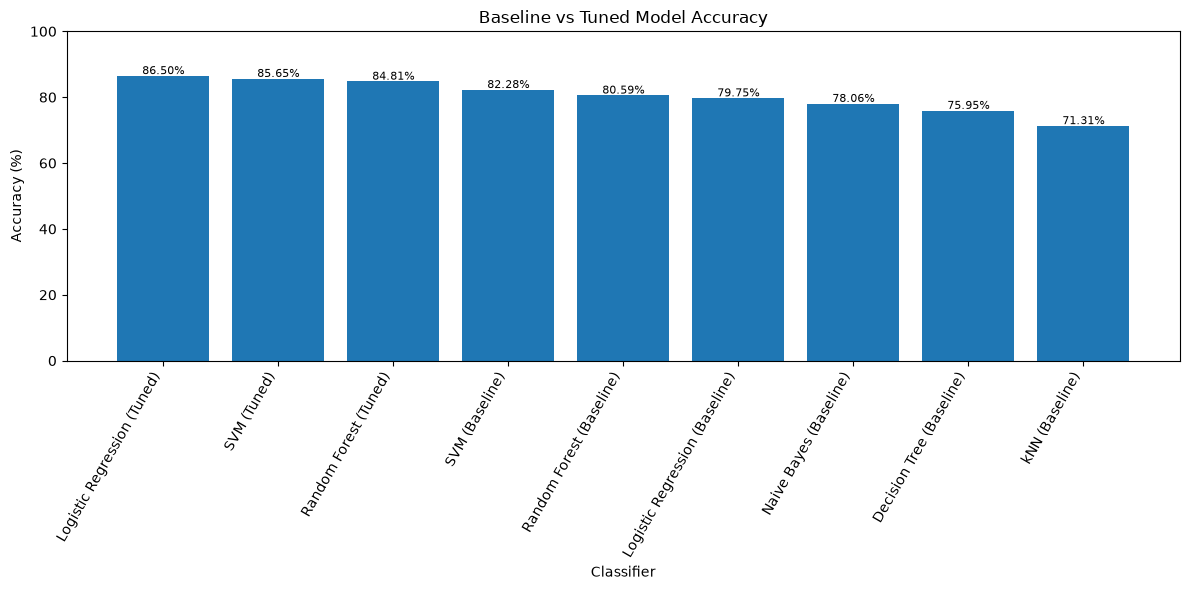

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.xlabel("Classifier")
plt.ylabel("Accuracy (%)")
plt.title("Baseline vs Tuned Model Accuracy")
plt.xticks(rotation=60, ha="right")
plt.ylim(0, 100)

for i, value in enumerate(results_df["Accuracy"]):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center", fontsize=8)

plt.tight_layout()
plt.show()

## 9. Confusion Matrix Analysis

Confusion matrices are used to evaluate the classification performance of each model by comparing the actual and predicted classes. They help identify correctly classified papers and the categories that are most frequently misclassified.

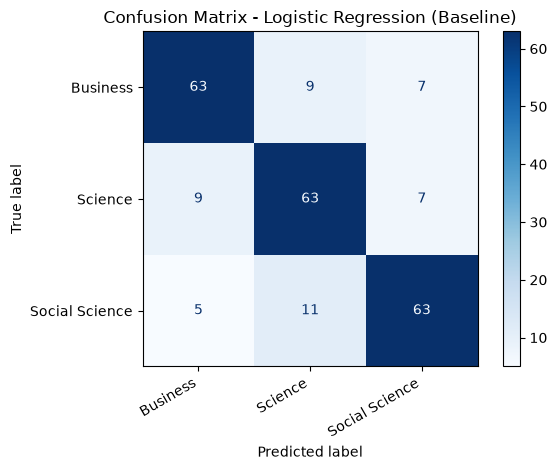

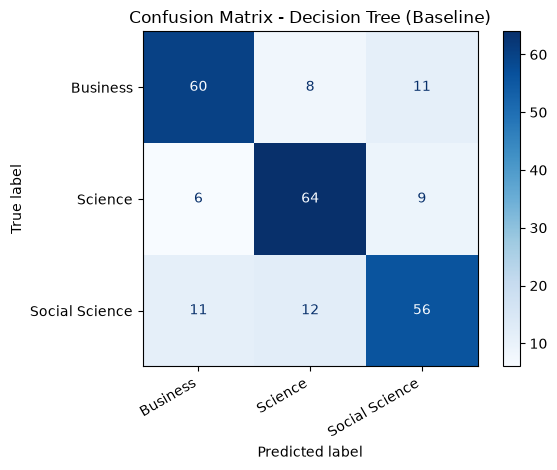

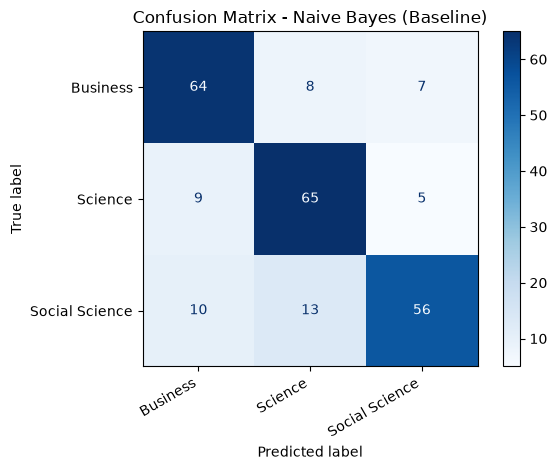

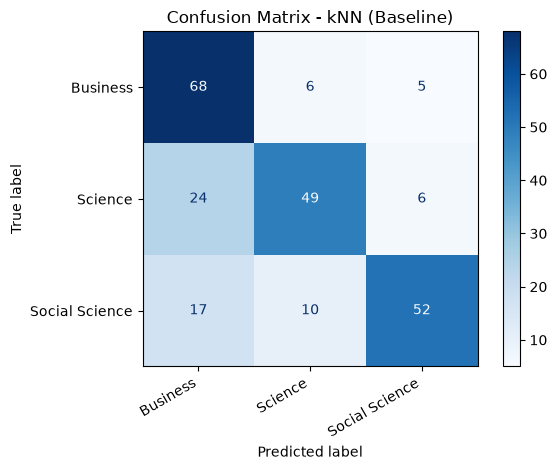

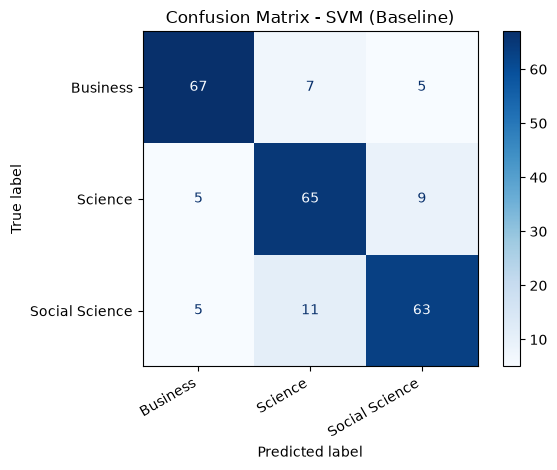

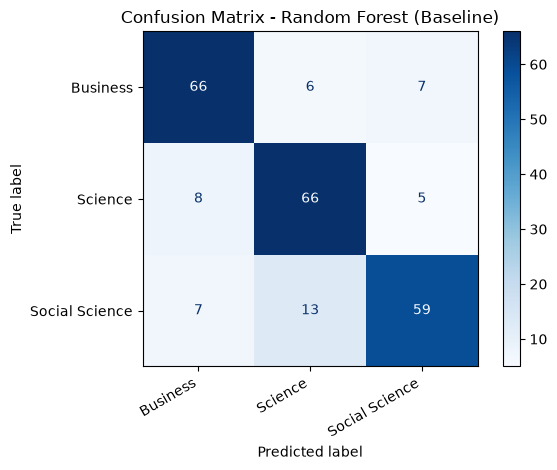

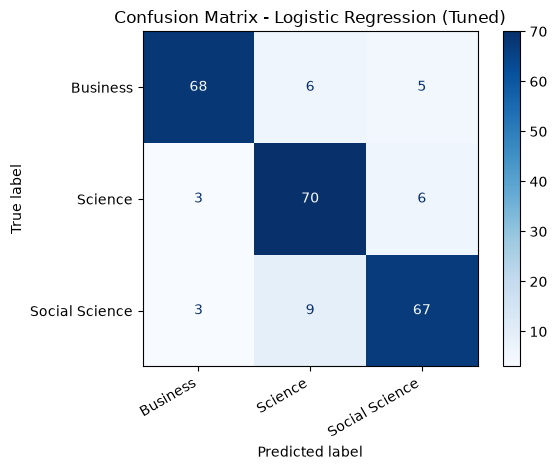

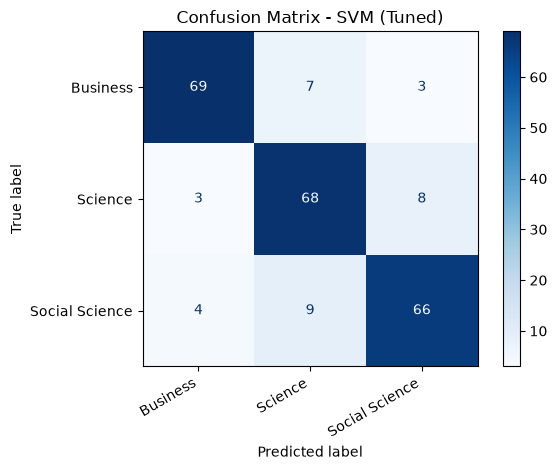

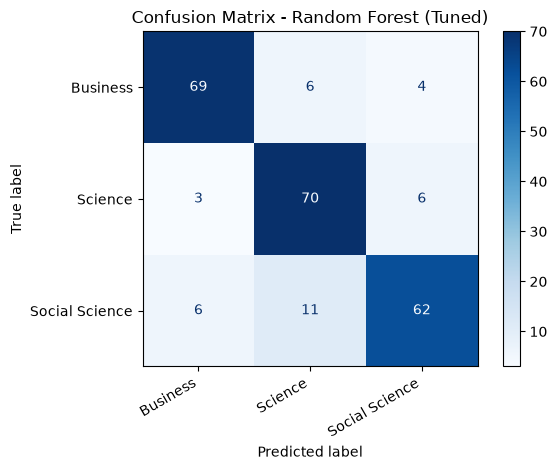

In [45]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

all_models = {
    "Logistic Regression (Baseline)": y_pred_lr,
    "Decision Tree (Baseline)": y_pred_dt,
    "Naive Bayes (Baseline)": y_pred_nb,
    "kNN (Baseline)": y_pred_knn,
    "SVM (Baseline)": y_pred_svm,
    "Random Forest (Baseline)": y_pred_rf,
    "Logistic Regression (Tuned)": y_pred_lr_tuned,
    "SVM (Tuned)": y_pred_svm_tuned,
    "Random Forest (Tuned)": y_pred_rf_tuned
}

labels = ["Business", "Science", "Social Science"]

for name, predictions in all_models.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=labels,
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## 10. Research Abstract Prediction Demo

The trained Logistic Regression model is used to classify research papers from uploaded PDF files. The abstract is extracted from the PDF, processed, and passed to the model to predict whether the paper belongs to Science, Business, or Social Science.

In [46]:
import ipywidgets as widgets
from IPython.display import display

best_lr = lr_grid_search.best_estimator_

print("Selected model:", type(best_lr.named_steps["classifier"]).__name__)

Selected model: LogisticRegression


The best Logistic Regression model obtained through hyperparameter tuning is selected for the prediction demo. This trained model is used to classify new research abstracts into one of the three predefined categories: Science, Business, or Social Science.

In [47]:
pdf_upload = widgets.FileUpload(
    accept=".pdf",
    multiple=False,
    description="Upload Paper"
)

display(pdf_upload)

FileUpload(value=(), accept='.pdf', description='Upload Paper')

A PDF upload widget is provided to allow users to upload a research paper. The uploaded file is read directly from memory, eliminating the need to save it as a separate file before processing.

In [54]:
from io import BytesIO
import re
import PyPDF2

def extract_abstract(pdf_bytes):
    reader = PyPDF2.PdfReader(BytesIO(pdf_bytes))

    text = ""
    for page in reader.pages:
        text += (page.extract_text() or "") + "\n"

    # Join words split across lines
    text = re.sub(r"(?<=\w)-\s*\n\s*(?=\w)", "", text)
    text = re.sub(r"\s+", " ", text)

    match = re.search(
        r"\babstract\b\s*:?\s*(.*?)"
        r"(?=\b(?:keywords|index terms|introduction)\b)",
        text,
        re.IGNORECASE
    )

    if match:
        return match.group(1).strip()

    return None

The text is extracted from the uploaded PDF using PyPDF2. A regular expression is used to locate the abstract section by identifying the "Abstract" heading and its possible ending markers, such as "Keywords", "Index Terms", or "Introduction". The extracted text is then cleaned by joining words split across lines and removing unnecessary whitespace.

In [53]:
def predict_pdf(change=None):
    if not pdf_upload.value:
        print("Please upload a PDF first.")
        return

    file_info = pdf_upload.value[0]

    pdf_bytes = bytes(file_info["content"])

    abstract = extract_abstract(pdf_bytes)

    if not abstract:
        print("Could not find the abstract in this PDF.")
        return

    prediction = best_lr.predict([abstract])[0]

    print("Extracted Abstract:")
    print(abstract)
    print("\nPredicted Category:", prediction)

The extracted abstract is passed to the trained Logistic Regression model. The model applies the same TF-IDF transformation used during training and predicts the research paper's category based on its textual features.

In [52]:
predict_pdf()

Extracted Abstract:
—Massive amounts of data are being generated these days all around the world. The majority of social networking platforms, ecommerce sites, the public and private sectors, healthcare institutions, cloud networks, and various servers are all generating immense amounts of data. Collected data from various sites could be in a structured or unstructured format. Extract-Transform-Load (ETL) is a crucial component of the growing demand for quicker business decisions aimed at many contemporary applications. Due to the volume and speed of data, real-time ETL is built on the foundation of multi-source, unstructured data stream extraction and transformation employing disc data in dispersed environments. The entire procedure is pipelined while processing so that the final resultant data can provide some essential and useful conclusions to work on. This paper presents a cloud-based data lake and analytics solution developed using Amazon Web Services (AWS) that addresses these c

The extracted abstract and its predicted category: Business, is displayed here. This provides a simple demonstration of how the trained model can be used to automatically classify an unseen research paper, that is, my own research paper(unpublished).

## Conclusion

This project presents a machine learning-based approach for automatically classifying research papers into three categories: **Science, Business, and Social Science**. The Scopus research paper dataset is preprocessed using text cleaning, stop-word removal, and lemmatization to improve the quality of textual features.

TF-IDF is used to convert the cleaned abstracts into numerical representations. Six machine learning classifiers are trained and evaluated, followed by hyperparameter tuning of Logistic Regression, Linear SVM, and Random Forest using GridSearchCV with 5-fold cross-validation. The tuned Logistic Regression model achieves the highest test accuracy of **86.50%**, along with a cross-validation macro F1-score of **0.7935**.

The project also includes a research abstract prediction demo that extracts an abstract from an uploaded PDF and predicts its category using the trained Logistic Regression model. This demonstrates how machine learning can assist in organizing and categorizing research literature.

Overall, the results show that TF-IDF combined with classical machine learning algorithms provides an effective approach for research paper classification. The project establishes a foundation for further improvements, such as incorporating larger datasets, exploring advanced language models, and extending the system to support more research domains.